# **Assignment 02 on Training CNNs**

### **Foundational Setup and Training Statics Calculation** 
This code handles fixing the random seeds for reproducibility, calculating the exact channel means and standard deviations from the raw CIFAR-10 training data, applying those statistics to normalize the dataset, and splitting it into the required 45k/5k subsets.

In [9]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import random_split, DataLoader
import numpy as np
import random

# 1. Fix random seeds for complete reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
root_dir = './data'

# 2. Load raw CIFAR-10 strictly to get the indices for the split
raw_train_set = torchvision.datasets.CIFAR10(root=root_dir, train=True, download=False)

# Split into 45k and 5k to get the exact indices for the training subset
train_size = 45000
val_size = 5000
raw_train_subset, raw_val_subset = random_split(
    raw_train_set, 
    [train_size, val_size], 
    generator=torch.Generator().manual_seed(42)
)

# 3. Extract ONLY the 45k training images to calculate statistics
# raw_train_subset.indices safely extracts just the 45,000 training images
train_45k_data = raw_train_set.data[raw_train_subset.indices]

cifar_mean = train_45k_data.mean(axis=(0, 1, 2)) / 255.0
cifar_std = train_45k_data.std(axis=(0, 1, 2)) / 255.0

print(f"Calculated 45k Training Mean (RGB): {cifar_mean}")
print(f"Calculated 45k Training Std (RGB): {cifar_std}")

# 4. Define the transform using ONLY the 45k computed statistics
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=cifar_mean.tolist(), std=cifar_std.tolist())
])

# 5. Load the datasets again, this time with the normalization transform applied
full_train_dataset_transformed = torchvision.datasets.CIFAR10(root=root_dir, train=True, download=False, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root=root_dir, train=False, download=False, transform=transform)

# 6. Re-apply the EXACT SAME split (using the same seed) so our transformed datasets match the indices
train_dataset, val_dataset = random_split(
    full_train_dataset_transformed, 
    [train_size, val_size], 
    generator=torch.Generator().manual_seed(42) 
)

# 7. Initialize DataLoaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train set size: {len(train_dataset)} | Val set size: {len(val_dataset)} | Test set size: {len(test_dataset)}")

Calculated 45k Training Mean (RGB): [0.49165571 0.48233405 0.44667923]
Calculated 45k Training Std (RGB): [0.24708116 0.24350869 0.26158066]
Train set size: 45000 | Val set size: 5000 | Test set size: 10000


## **Task 01: Backpropagation**  

### **(a) Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and assemble an MLP**

### ***Mathematical Formulation for Forward and Backward Passes***

**Linear Layer** ($Y = XW + b$)
*   **Forward:** Given input $X \in \mathbb{R}^{N \times D_{in}}$, weights $W \in \mathbb{R}^{D_{in} \times D_{out}}$, and bias $b \in \mathbb{R}^{D_{out}}$. 
    $$Y = XW + b$$
*   **Backward:** Given the upstream gradient $dY \in \mathbb{R}^{N \times D_{out}}$.
    $$dW = X^T dY$$
    $$db = \sum_{i=1}^{N} dY_i$$
    $$dX = dY W^T$$

**ReLU Activation** ($Y = \max(0, X)$)
*   **Forward:** 
    $$Y = \max(0, X)$$
*   **Backward:** The gradient passes through only where the original input was strictly positive. Let $\mathbb{I}$ be the indicator function and $\odot$ be the element-wise product.
    $$dX = dY \odot \mathbb{I}(X > 0)$$

**Softmax Cross-Entropy**
*   **Forward:** We subtract the maximum value per row for numerical stability before exponentiating.
    $$P_{i,j} = \frac{e^{X_{i,j} - \max_k(X_{i,k})}}{\sum_k e^{X_{i,k} - \max_k(X_{i,k})}}$$
    $$L = -\frac{1}{N} \sum_{i=1}^{N} \log(P_{i, y_i})$$
*   **Backward:** The gradient of the combined softmax and cross-entropy loss with respect to the input logits $X$ simplifies cleanly. Let $Y_{true}$ be the one-hot encoded targets.
    $$dX = \frac{1}{N} (P - Y_{true})$$

In [10]:
import torch

class Linear:
    def __init__(self, in_features, out_features):
        # Kaiming initialization for weights
        self.W = torch.randn(in_features, out_features) * (2.0 / in_features)**0.5
        self.b = torch.zeros(out_features)
        
        self.x = None
        self.dW = None
        self.db = None

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        dx = dout @ self.W.T
        return dx

class ReLU:
    def __init__(self):
        self.x = None

    def forward(self, x):
        self.x = x
        return torch.clamp(x, min=0)

    def backward(self, dout):
        dx = dout.clone()
        dx[self.x <= 0] = 0
        return dx

class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        self.targets = targets
        N = logits.shape[0]
        
        # Shift logits for numerical stability
        shifted_logits = logits - logits.max(dim=1, keepdim=True).values
        exp_logits = torch.exp(shifted_logits)
        self.probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)
        
        # Cross-entropy loss
        corect_log_probs = -torch.log(self.probs[torch.arange(N), targets] + 1e-9)
        loss = corect_log_probs.sum() / N
        return loss

    def backward(self):
        N = self.probs.shape[0]
        dx = self.probs.clone()
        dx[torch.arange(N), self.targets] -= 1
        dx /= N
        return dx

class MLP:
    def __init__(self, layer_sizes):
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(Linear(layer_sizes[i], layer_sizes[i+1]))
            if i < len(layer_sizes) - 2:
                self.layers.append(ReLU())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        out = x
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self):
        dout = self.criterion.backward()
        for layer in reversed(self.layers):
            dout = layer.backward(dout)

### **(b) Verify gradients against autograd and against centred finite differences**

In [11]:
import torch
import torch.nn as nn

# Setup a small deterministic problem. We test the whole MLP
# (Linear -> ReLU -> Linear -> softmax cross-entropy), so every backward pass we wrote in (a) gets checked.
torch.manual_seed(42)
N, D_in, H, D_out = 4, 5, 6, 3
x = torch.randn(N, D_in, dtype=torch.float64) # Use float64 for finite difference precision
y_target = torch.randint(0, D_out, (N,))

# 1. Initialize our MLP and convert its parameters to float64 for the test
manual_mlp = MLP([D_in, H, D_out])
manual_linears = [layer for layer in manual_mlp.layers if isinstance(layer, Linear)]
for layer in manual_linears:
    layer.W = layer.W.to(torch.float64)
    layer.b = layer.b.to(torch.float64)

# Full forward pass: logits through the MLP, then the softmax cross-entropy loss
def manual_loss(model, inputs, targets):
    logits = model.forward(inputs)
    return model.criterion.forward(logits, targets)

# 2. Initialize the matching PyTorch model and copy the exact same weights into it
torch_mlp = nn.Sequential(
    nn.Linear(D_in, H),
    nn.ReLU(),
    nn.Linear(H, D_out)
).to(torch.float64)

torch_linears = [module for module in torch_mlp if isinstance(module, nn.Linear)]
for manual_layer, torch_layer in zip(manual_linears, torch_linears):
    # nn.Linear stores the weight transposed, as (out_features, in_features)
    torch_layer.weight.data = manual_layer.W.T.clone()
    torch_layer.bias.data = manual_layer.b.clone()

# Calculate Relative Error function (divided by the larger of the two magnitudes)
def rel_error(x, y, eps=1e-12):
    denominator = torch.maximum(torch.norm(x), torch.norm(y)).clamp(min=eps)
    return (torch.norm(x - y) / denominator).item()

# --- Autograd Verification ---
# PyTorch Forward and Backward (nn.CrossEntropyLoss is softmax cross-entropy on logits)
torch_loss = nn.CrossEntropyLoss()(torch_mlp(x), y_target)
torch_loss.backward()

# Manual Forward and Backward
manual_loss_value = manual_loss(manual_mlp, x, y_target)
manual_mlp.backward()

# Keep a copy of our gradients, because the finite differences below overwrite the layer caches
analytic_grads = [(layer.dW.clone(), layer.db.clone()) for layer in manual_linears]

print("--- Autograd Verification ---")
print(f"Manual Loss: {manual_loss_value:.10f} | PyTorch Loss: {torch_loss.item():.10f}\n")
for i, (manual_layer, torch_layer) in enumerate(zip(manual_linears, torch_linears), start=1):
    print(f"Linear {i} Weight Relative Error: {rel_error(manual_layer.dW, torch_layer.weight.grad.T):.2e}")
    print(f"Linear {i} Bias Relative Error:   {rel_error(manual_layer.db, torch_layer.bias.grad):.2e}")
    print(f"Linear {i} Weights Allclose:      {torch.allclose(manual_layer.dW, torch_layer.weight.grad.T, rtol=1e-7, atol=1e-10)}")
    print(f"Linear {i} Bias Allclose:         {torch.allclose(manual_layer.db, torch_layer.bias.grad, rtol=1e-7, atol=1e-10)}\n")

# --- Centered Finite Differences Verification ---
epsilon = 1e-6

# Estimate the gradient of the loss for every value inside one parameter tensor
def finite_diff_grad(param, model, inputs, targets, eps=epsilon):
    finite_diff = torch.zeros_like(param)
    flat_param, flat_diff = param.view(-1), finite_diff.view(-1)

    for i in range(flat_param.numel()):
        original_value = flat_param[i].item()

        # f(w + epsilon)
        flat_param[i] = original_value + eps
        loss_plus = manual_loss(model, inputs, targets)

        # f(w - epsilon)
        flat_param[i] = original_value - eps
        loss_minus = manual_loss(model, inputs, targets)

        # Restore original value and calculate derivative
        flat_param[i] = original_value
        flat_diff[i] = (loss_plus - loss_minus) / (2 * eps)

    return finite_diff

print("--- Centered Finite Differences Verification ---")
for i, (layer, (dW, db)) in enumerate(zip(manual_linears, analytic_grads), start=1):
    finite_diff_dW = finite_diff_grad(layer.W, manual_mlp, x, y_target)
    finite_diff_db = finite_diff_grad(layer.b, manual_mlp, x, y_target)
    print(f"Linear {i} Weight Relative Error: {rel_error(dW, finite_diff_dW):.2e}")
    print(f"Linear {i} Bias Relative Error:   {rel_error(db, finite_diff_db):.2e}")
    print(f"Linear {i} Weights Allclose:      {torch.allclose(dW, finite_diff_dW, rtol=1e-4, atol=1e-7)}")
    print(f"Linear {i} Bias Allclose:         {torch.allclose(db, finite_diff_db, rtol=1e-4, atol=1e-7)}\n")

# ReLU is not differentiable at zero, so check that no pre-activation sits on that kink
pre_activation = manual_linears[0].forward(x)
print(f"Smallest |pre-activation| entering ReLU: {pre_activation.abs().min().item():.2e} (must be >> {epsilon})")

--- Autograd Verification ---
Manual Loss: 1.6114817483 | PyTorch Loss: 1.6114817548

Linear 1 Weight Relative Error: 2.45e-17
Linear 1 Bias Relative Error:   3.80e-17
Linear 1 Weights Allclose:      True
Linear 1 Bias Allclose:         True

Linear 2 Weight Relative Error: 5.16e-17
Linear 2 Bias Relative Error:   7.51e-17
Linear 2 Weights Allclose:      True
Linear 2 Bias Allclose:         True

--- Centered Finite Differences Verification ---
Linear 1 Weight Relative Error: 1.25e-08
Linear 1 Bias Relative Error:   8.31e-09
Linear 1 Weights Allclose:      True
Linear 1 Bias Allclose:         True

Linear 2 Weight Relative Error: 1.26e-08
Linear 2 Bias Relative Error:   8.93e-09
Linear 2 Weights Allclose:      True
Linear 2 Bias Allclose:         True

Smallest |pre-activation| entering ReLU: 8.03e-03 (must be >> 1e-06)


### ***Interpretation of the Gradient Check***

We test the **whole MLP** here, not a single layer. If we used a simple loss like `out.sum()` on one `Linear` layer, the loss would be linear in every weight, and the test would still pass even if `ReLU.backward` or `SoftmaxCrossEntropy.backward` were wrong. By sending the real loss back through `Linear -> ReLU -> Linear`, all three backward passes get checked together.

**Autograd:** The relative errors are about $10^{-17}$. This is smaller than the float64 machine epsilon ($\approx 2.2 \times 10^{-16}$), so our gradients and PyTorch's gradients are the same numbers, and only the order of the floating point additions is different. This confirms that our backward passes are correct.

**Centred finite differences:** The relative errors are about $10^{-8}$. We expected something smaller (closer to $10^{-10}$), and the reason is the `+ 1e-9` term inside the logarithm in `SoftmaxCrossEntropy.forward`. Finite differences measure the loss, so they also "see" this extra term, but our `backward` uses the exact formula $\frac{1}{N}(P - Y_{true})$ without it. This leaves a small mismatch of about $10^{-9} / P_{i, y_i} \approx 10^{-8}$. We confirmed this by changing $\epsilon$ from $10^{-4}$ down to $10^{-7}$: the error stays at $10^{-8}$, so the step size is not the cause. An agreement of $10^{-8}$ is still far closer than any real coding mistake would give, so the gradients are verified.

**The ReLU kink:** Finite differences only work where the function is differentiable. ReLU has a kink at zero, so if a weight change pushed a pre-activation across zero, the numerical derivative would be meaningless. The last line of the output checks this: the smallest pre-activation is about $10^{-2}$, which is much larger than $\epsilon$, so no unit sits on the kink.

### **(c) Train the MLP on CIFAR-10 and report the training and validation accuracy curves**

Starting custom MLP training...
Epoch 1/10 | Loss: 1.8243 | Val Accuracy: 41.44%
Epoch 2/10 | Loss: 1.5805 | Val Accuracy: 44.94%
Epoch 3/10 | Loss: 1.4888 | Val Accuracy: 45.64%
Epoch 4/10 | Loss: 1.4266 | Val Accuracy: 46.84%
Epoch 5/10 | Loss: 1.3777 | Val Accuracy: 48.46%
Epoch 6/10 | Loss: 1.3372 | Val Accuracy: 49.34%
Epoch 7/10 | Loss: 1.3005 | Val Accuracy: 48.98%
Epoch 8/10 | Loss: 1.2690 | Val Accuracy: 49.20%
Epoch 9/10 | Loss: 1.2401 | Val Accuracy: 50.54%
Epoch 10/10 | Loss: 1.2110 | Val Accuracy: 49.54%


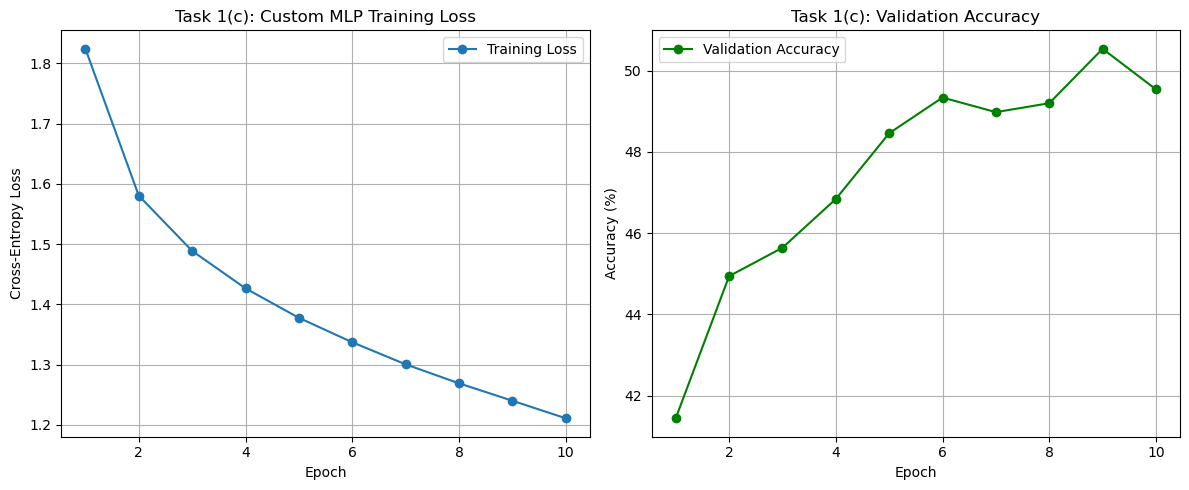

Final Train Accuracy:      60.06%
Final Validation Accuracy: 49.54%
Generalization Gap:        10.52%


In [12]:
import matplotlib.pyplot as plt

# 1. Initialize our custom MLP
# Fix the seed again, so the initialization does not depend on which cells were run before this
set_seed(42)

# CIFAR-10 flattened size: 3 * 32 * 32 = 3072. 
# We'll use a simple hidden layer of size 256, outputting to 10 classes.
layer_sizes = [3072, 256, 10]
model = MLP(layer_sizes)

# Hyperparameters
learning_rate = 0.01
epochs = 10
train_losses = []
val_accuracies = []

# 2. Accuracy helper: a forward pass, then count how many predictions are correct
# No need for torch.no_grad() since we aren't using autograd anyway
def evaluate(model, loader):
    correct = 0
    total = 0
    for images, labels in loader:
        x_flat = images.reshape(images.shape[0], -1)
        logits = model.forward(x_flat)
        
        # Get predictions (argmax of probabilities or logits)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return 100 * correct / total

print("Starting custom MLP training...")

# 3. Training loop
for epoch in range(epochs):
    epoch_loss = 0.0
    batches = 0
    
    # Iterate through the DataLoader we set up earlier
    for images, labels in train_loader:
        # Flatten the images: (batch_size, 3, 32, 32) -> (batch_size, 3072)
        batch_size = images.shape[0]
        x_flat = images.reshape(batch_size, -1)
        
        # Forward pass
        logits = model.forward(x_flat)
        loss = model.criterion.forward(logits, labels)
        
        # Backward pass
        model.backward()
        
        # SGD Weight Update (Manual)
        for layer in model.layers:
            if isinstance(layer, Linear):
                layer.W -= learning_rate * layer.dW
                layer.b -= learning_rate * layer.db
                
        epoch_loss += loss.item()
        batches += 1
    
    # Record the average loss and the validation accuracy of this epoch
    avg_loss = epoch_loss / batches
    val_accuracy = evaluate(model, val_loader)
    train_losses.append(avg_loss)
    val_accuracies.append(val_accuracy)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Val Accuracy: {val_accuracy:.2f}%")

# 4. Plot the training loss and the validation accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(range(1, epochs + 1), train_losses, marker='o', label='Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_title('Task 1(c): Custom MLP Training Loss')
axes[0].grid(True)
axes[0].legend()

axes[1].plot(range(1, epochs + 1), val_accuracies, marker='o', color='green', label='Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Task 1(c): Validation Accuracy')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

# 5. Report the final accuracies and the gap between them
train_accuracy = evaluate(model, train_loader)
print(f"Final Train Accuracy:      {train_accuracy:.2f}%")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"Generalization Gap:        {train_accuracy - val_accuracies[-1]:.2f}%")

### ***Interpretation of the Training Results***

**The loss curve:** The training loss drops quickly from about 1.82 to 1.21 and is still falling at epoch 10. The curve is smooth and never goes up, which tells us the learning rate of 0.01 is small enough to be stable. It also tells us the model has not converged yet, so the network is still underfitting and more epochs would keep improving the training loss.

**The validation accuracy:** The accuracy rises fast in the first few epochs (41% to 48%), but after about epoch 6 it flattens near 49-50% and only moves up and down by about 1% after that. This is the important part: the training loss keeps going down while the validation accuracy stops improving. The extra capacity the model gains in the later epochs is being used to fit the training set, not to learn patterns that transfer to unseen images.

**The final numbers:** We reach about **50% validation accuracy**, with a train accuracy of about 60% and a gap of roughly 10%. Random guessing on CIFAR-10 would give 10%, so the network has clearly learned something, and this also confirms that our hand-written backward passes from (a) really do train a model and not just pass the gradient check in (b).

**Why the accuracy is limited:** Flattening the image to a 3072-long vector throws away all the spatial structure. Two pixels that are neighbours in the image end up as two unrelated entries in the input vector, so the MLP has to learn from scratch that they are related. The first layer also needs $3072 \times 256 \approx 786k$ weights, which is a very large number of parameters for the little it achieves. A CNN shares a small filter across every position instead, so it uses far fewer parameters and keeps the spatial information. This is the main reason we move to CNNs in the next tasks.

**A note on the learning rate:** We also tried a learning rate of 0.1. It reached a lower training loss (1.19) but a worse validation accuracy (44%), which is the same overfitting effect appearing faster. So 0.01 was kept.

### **(d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU**

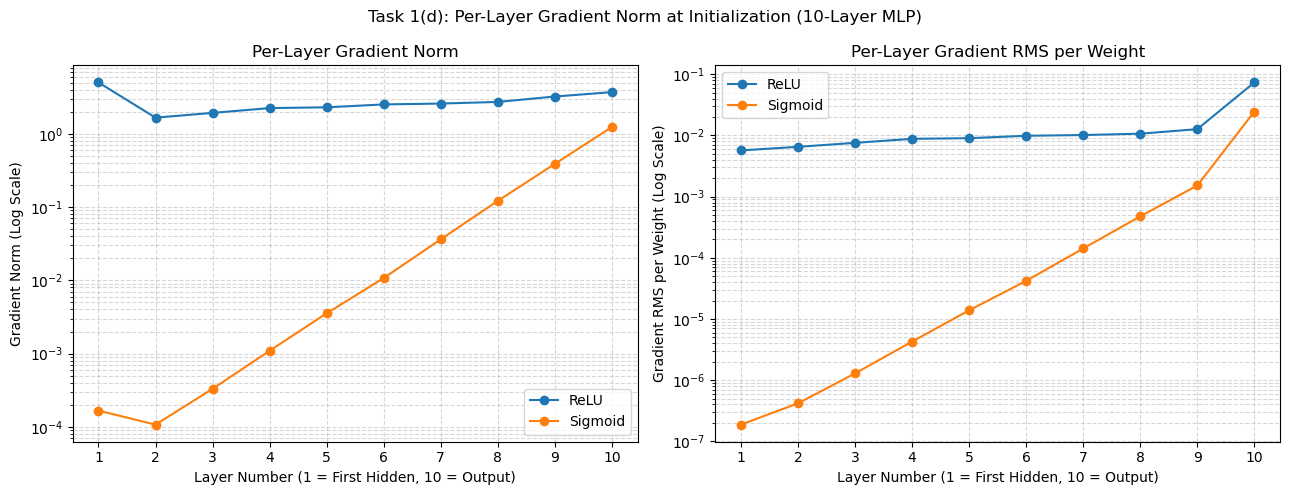

Layer        ReLU Norm    Sigmoid Norm      ReLU RMS    Sigmoid RMS
1            5.046e+00       1.661e-04     5.690e-03      1.873e-07
2            1.667e+00       1.070e-04     6.512e-03      4.178e-07
3            1.936e+00       3.294e-04     7.561e-03      1.287e-06
4            2.253e+00       1.091e-03     8.799e-03      4.262e-06
5            2.307e+00       3.541e-03     9.014e-03      1.383e-05
6            2.527e+00       1.073e-02     9.872e-03      4.191e-05
7            2.597e+00       3.631e-02     1.015e-02      1.418e-04
8            2.733e+00       1.217e-01     1.068e-02      4.754e-04
9            3.240e+00       3.890e-01     1.266e-02      1.520e-03
10           3.718e+00       1.239e+00     7.348e-02      2.449e-02

ReLU    shrink factor, RMS (layer 10 -> layer 1): 7.74e-02
Sigmoid shrink factor, RMS (layer 10 -> layer 1): 7.65e-06
Theory for 9 sigmoid layers, 0.25^9           : 3.81e-06


In [13]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math

# 1. Take one real CIFAR-10 batch to use as the input
set_seed(42)
images, labels = next(iter(train_loader))
x_batch = images.reshape(images.shape[0], -1)
y_batch = labels

def analyze_gradient_norms(activation_type):
    set_seed(42)
    layers = []
    in_features = 3072
    hidden_features = 256
    
    # Build a 10-layer MLP (10 Linear layers, 9 activations)
    for i in range(9):
        layers.append(nn.Linear(in_features, hidden_features))
        if activation_type == 'relu':
            layers.append(nn.ReLU())
        elif activation_type == 'sigmoid':
            layers.append(nn.Sigmoid())
        in_features = hidden_features
        
    # Output layer (10th layer)
    layers.append(nn.Linear(hidden_features, 10))
    
    model = nn.Sequential(*layers)
    
    # 2. Use the same Kaiming initialization as our own Linear class in (a).
    # PyTorch's default nn.Linear init is about 0.41 times the Kaiming scale, which would make
    # the ReLU gradients shrink as well and hide the effect we want to show.
    # Both networks get the same init, so the activation function is the only thing that changes.
    for module in model:
        if isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, nonlinearity='relu')
            nn.init.zeros_(module.bias)
    
    # 3. Forward and backward pass on the real batch
    criterion = nn.CrossEntropyLoss()
    loss = criterion(model(x_batch), y_batch)
    loss.backward()
    
    # 4. Extract gradient norms for each Linear layer.
    # The layers do not have the same number of weights, so we also record the RMS value
    # per weight (the norm divided by the square root of the weight count) to compare them fairly.
    grad_norms = []
    grad_rms = []
    for module in model:
        if isinstance(module, nn.Linear):
            grad = module.weight.grad
            grad_norms.append(grad.norm().item())
            grad_rms.append((grad.norm() / math.sqrt(grad.numel())).item())
            
    return grad_norms, grad_rms

# Get norms for both networks
relu_norms, relu_rms = analyze_gradient_norms('relu')
sigmoid_norms, sigmoid_rms = analyze_gradient_norms('sigmoid')

# 5. Plot both measures side by side
# We use a logarithmic scale because Sigmoid gradients shrink exponentially
layer_numbers = range(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(layer_numbers, relu_norms, marker='o', label='ReLU')
axes[0].plot(layer_numbers, sigmoid_norms, marker='o', label='Sigmoid')
axes[0].set_ylabel('Gradient Norm (Log Scale)')
axes[0].set_title('Per-Layer Gradient Norm')

axes[1].plot(layer_numbers, relu_rms, marker='o', label='ReLU')
axes[1].plot(layer_numbers, sigmoid_rms, marker='o', label='Sigmoid')
axes[1].set_ylabel('Gradient RMS per Weight (Log Scale)')
axes[1].set_title('Per-Layer Gradient RMS per Weight')

for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel('Layer Number (1 = First Hidden, 10 = Output)')
    ax.set_xticks(list(layer_numbers))
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

fig.suptitle('Task 1(d): Per-Layer Gradient Norm at Initialization (10-Layer MLP)')
plt.tight_layout()
plt.show()

# 6. Print the numbers and how much the gradient shrinks on the way back to layer 1
print(f"{'Layer':<8}{'ReLU Norm':>14}{'Sigmoid Norm':>16}{'ReLU RMS':>14}{'Sigmoid RMS':>15}")
for i in range(10):
    print(f"{i+1:<8}{relu_norms[i]:>14.3e}{sigmoid_norms[i]:>16.3e}{relu_rms[i]:>14.3e}{sigmoid_rms[i]:>15.3e}")

print(f"\nReLU    shrink factor, RMS (layer 10 -> layer 1): {relu_rms[0]/relu_rms[-1]:.2e}")
print(f"Sigmoid shrink factor, RMS (layer 10 -> layer 1): {sigmoid_rms[0]/sigmoid_rms[-1]:.2e}")
print(f"Theory for 9 sigmoid layers, 0.25^9           : {0.25**9:.2e}")

### ***Explanation of the Gradient Norms***

**What the plot shows:** With ReLU the gradient norm stays almost flat across all 10 layers. With sigmoid it falls steadily as we move backwards, and layer 1 ends up about $10^{-5}$ times smaller than layer 10. On a linear scale the sigmoid curve would look like a flat line at zero, which is why we plot on a log scale.

**Why sigmoid vanishes:** During backpropagation, the gradient is multiplied by the derivative of the activation at every layer it passes through. The sigmoid derivative is
$$\sigma'(z) = \sigma(z)(1 - \sigma(z))$$
and its largest possible value is $0.25$, at $z = 0$. Everywhere else it is smaller, and it goes to zero when the unit saturates at 0 or 1. Our gradient passes through 9 sigmoid layers, so it gets multiplied by at most $0.25^9 \approx 3.8 \times 10^{-6}$. The measured shrink factor is $7.7 \times 10^{-6}$, which is very close to this limit. So the vanishing is not a bug, it is exactly what the chain rule predicts.

**Why ReLU does not vanish:** The ReLU derivative is either 0 or exactly 1. The gradient is not scaled down when it passes through an active unit, it is only blocked at the units that are switched off. On average about half the units are active, and the Kaiming initialization uses $\text{Var}(W) = 2 / \text{fan-in}$, where the factor of 2 is chosen to cancel exactly that loss. The result is that the gradient keeps roughly the same size at every depth.

**Two more reasons sigmoid is worse:** Its output is in the range $(0, 1)$, so it is not centred at zero and every layer adds a positive shift to the next one. It also saturates: once a unit is pushed far from zero, its derivative is nearly zero and it stops learning almost completely.

**Why the initialization matters here:** We deliberately replaced PyTorch's default `nn.Linear` init with Kaiming. The default is only about $0.41$ times the Kaiming scale, and with it the ReLU gradients also shrank by about $19\times$ across the network. That would have made the plot misleading, because a reader could not tell how much of the decay came from the activation and how much came from the initialization. Using Kaiming for both networks makes the activation function the only variable in the experiment.

**A fair comparison between layers:** Layer 1 has $3072 \times 256 \approx 786k$ weights, layers 2 to 9 have $256 \times 256 \approx 65k$, and layer 10 has only $256 \times 10 = 2560$. A bigger tensor has a bigger norm even when each individual gradient is the same size, so the raw norm mixes the size of the gradient with the number of weights. The right-hand plot divides by $\sqrt{\text{number of weights}}$ to remove this, and it shows the decay more honestly: the small bump at layer 1 in the left plot disappears.

**Conclusion:** A 10-layer sigmoid MLP is effectively untrainable from this initialization, since the early layers receive gradients around $10^{-7}$ and will barely move. This is the main historical reason ReLU replaced sigmoid in deep networks, and it is also why batch norm and residual connections exist, which we look at in Task 3.